# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [1]:
import os
from datetime import datetime

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v2
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
# %aimport lassi.pipeline
%aimport lassi.pipeline_v2
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "jacobi"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = app_folder_name + "-cuda_main"  # "lid-driven-cavity-cuda_main"  # "jacobi-cuda_main"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2
    use_self_prompting = False  # True or False -- NOT USED IN v2
    use_context_summaries_only = True  # True or False
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    model = "gpto3mini"  # (max token = 200000)
    model_coder = "gpto3mini"  # (max token = 200000)
    model_judge = "gpto3mini"  # (max token = 200000)

    # -- FROM OLLAMA
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini", "gpto3mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "_t1.6_pipelineV2_o3mini_jacobi_" + llm_source + "_ee_hecb_selfcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 03-30-2025_t23_36_21
Application: jacobi

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto3mini
Model coder: gpto3mini
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True


***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****


----- WELCOME TO PIPELINE v2! CODE -----



----- SOURCE CODE: Test compile and execute -----

Test compile the original source code: sourc

Waiting for the system to settle down for 1 seconds...: 100%|█████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/jacobi
Execute command: ['./jacobi-cuda_main', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00400836 (s)
PASS
Total elapsed time: 7.745 seconds
GPU power data has been written to source_CUDA_gpu_power_results.csv


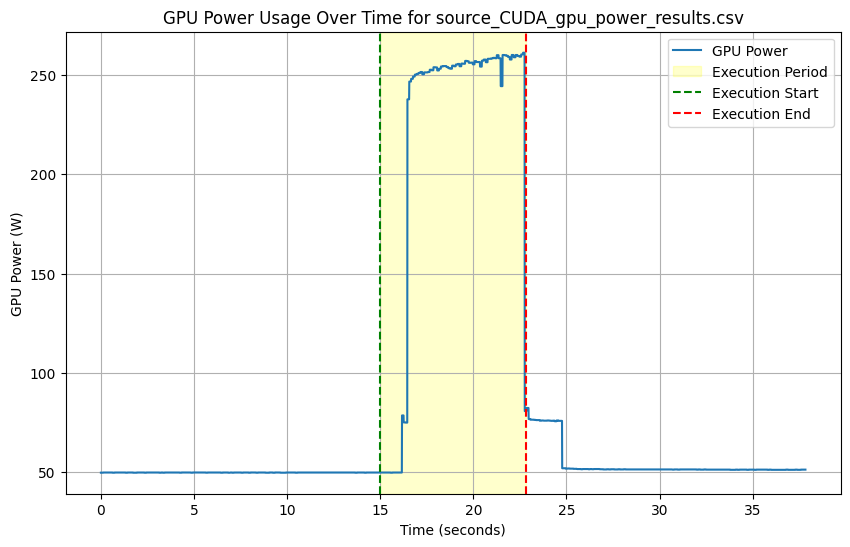

Start time: 15.001 -- End time: 22.832
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000470 kWh
  0.4704 Wh
  1693.44 J
Average GPU power: 216.27 W
Total Energy During Exe Runtime:   1693.44 J
Code execution duration: 7.83 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 7.83
GPU power data has been written to idle__gpu_power_results.csv


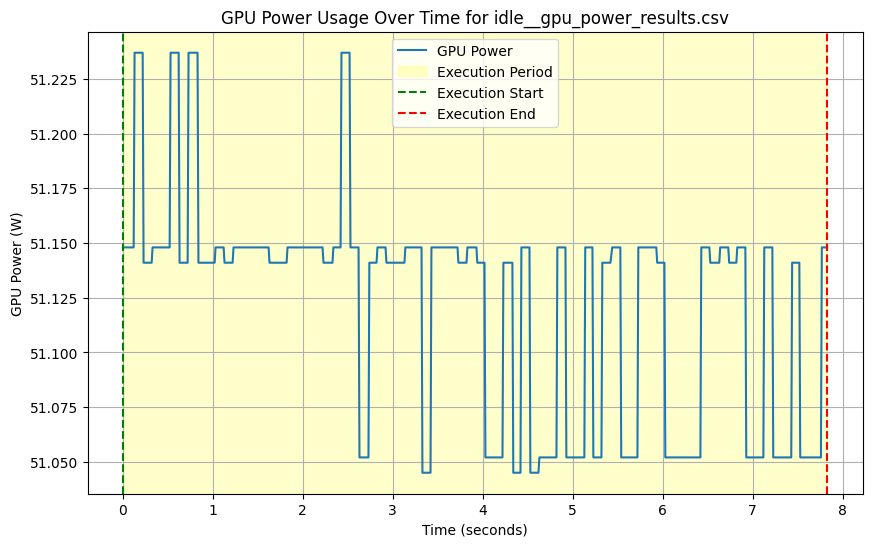

Start time: 0 -- End time: 7.832
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000111 kWh
  0.1113 Wh
  400.81 J
Average GPU power: 51.12 W
Total Energy During Exe Runtime:   400.81 J
Code execution duration: 7.83 seconds
----------------------------------------------------------------------------------------------------------------------------------------


----- STARTING FIRST STAGE: ZERO-SHOT BASE LLM REFACTORING -----


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 24): 


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00250183 (s)
PASS
Total elapsed time: 5.523 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


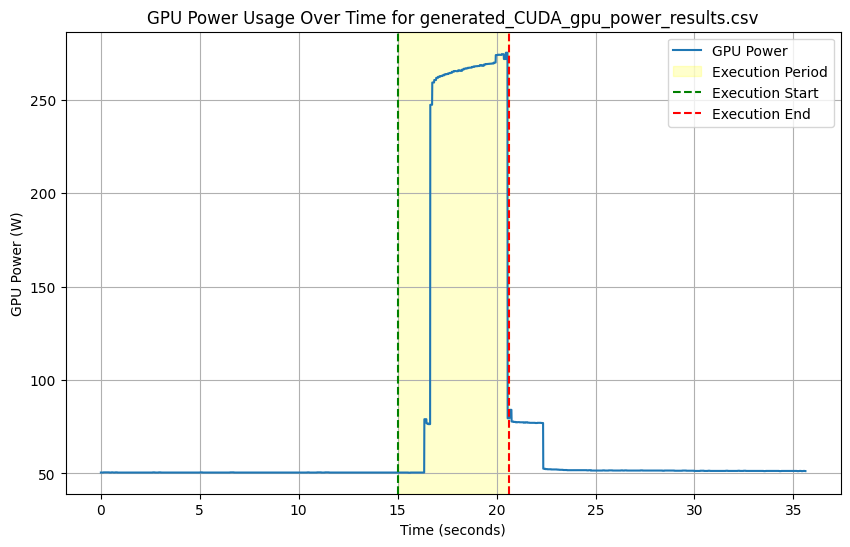

Start time: 15.001 -- End time: 20.611
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000316 kWh
  0.3162 Wh
  1138.14 J
Average GPU power: 202.87 W
Total Energy During Exe Runtime:   1138.14 J
Code execution duration: 5.61 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the following two codes written in CUDA C++.

    First, I will provide you first with the SOURCE CODE followed b



----- LLM RESPONSE: code validation judge -----



The refactored code is functionally equivalent to the original. Here is the reasoning:

1. Both versions initialize the arrays in the same way so that the sinusoidal boundary conditions and interior values are identical to start.

2. The Jacobi kernel in the refactored code preserves the same tile-based read, boundary (halo) loading, and computation as in the original. The change from hard-coded thread index checks (e.g. threadIdx.x == 15) to using blockDim.x‑1 is equivalent since the block dimensions are fixed at 16×16.

3. Instead of launching a separate swap_data kernel, the refactored version simply swaps the device pointers (using std::swap). This pointer swap is a standard approach that preserves the boundary (unchanged) values and transfers the computed interior values to the “old” array for the next iteration. This change does not affect the computed result or the printed standard output.

4. The printed standard output format (error messages every 1000 iterations, average execution time per iteration, PASS/FAIL message and final elapsed time) remains the same in layout and content. Any small differences in numerical timing values are consistent with improvements in energy efficiency and run-time performance.

Based on these points, the refactored code preserves all intended functionality and standard output.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1693.44
  Refactored code: 1138.14
----- Average power (W) -----
  Source code: 216.27
  Refactored code: 202.87
----- Runtime (s) -----
  Source code: 7.83
  Refactored code: 5.61
----- Tracking metrics -----
  Energy (J) history:  [1693.44, 1138.14]
  Ave Power (W) history:  [216.27, 202.87]
  Runtime (s) history:  [7.83, 5.61]
  Valid code history:  ['SOURCE', 'basellm_VALID']


***** Generated refactored code is more energy efficient than source or previous code! *****
... following refactor index: 0




CHANGE PROMPT STRATEGY! -----


----- STARTING LASSI: ITERATIVE SELF-PROMPTING WITH CONTEXT AND SELF-CORRECTION -----


--> ... prompt LLM to summarize context knowledge.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power c



----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



```
Key Points for Refactoring CUDA C++ Code for Energy Efficiency:

1. Minimize Memory Transfers:
   • Reduce data transfers between the host and the device.
   • Allocate and operate on intermediate data structures entirely in device memory.
   • Batch small transfers into a single larger transfer and use page-locked (pinned) memory for higher bandwidth.

2. Optimize Memory Usage:
   • Favor shared memory over global memory to reduce latency and energy consumption.
   • Minimize global memory accesses and use appropriate memory spaces (constant, texture) as needed.
   • Organize memory hierarchies so that data is as local as possible for GPU threads.

3. Efficient Kernel Launch Configurations:
   • Use thread block sizes that are multiples of 32 (warp size) to optimize execution efficiency.
   • Tailor grid and block dimensions to the problem size while maximizing occupancy.
   • Consider thread block clusters (when available) to leverage hardware-supported synchronization and reduce idle cycles.

4. Minimize Divergence and Conditional Overhead:
   • Write control flow to avoid warp divergence (e.g., by aligning conditions to warp boundaries).
   • When feasible, use branch predication or __syncwarp() (Volta and later) to ensure reconvergence with minimal overhead.

5. Use Asynchronous Operations:
   • Employ asynchronous memory copies (e.g., cudaMemcpyAsync) and compute operations to hide latency.
   • Manage synchronization carefully with CUDA’s asynchronous primitives and barriers.

6. Accelerated Math Operations:
   • Prefer fast math library functions and intrinsic versions (e.g., __sinf, __expf) when precision loss is acceptable.
   • Use specialized math functions (sincosf, sincospi) instead of generic ones and avoid costly operations like pow() in favor of explicit multiplication whenever possible.
   • Opt for single-precision math if double precision isn’t needed to reduce computational overhead.

7. Arithmetic and Loop Optimizations:
   • Use bit shifts in place of division/modulo when dealing with powers of two.
   • Use signed integers for loop counters to allow more aggressive compiler optimizations.
   • Manually unroll loops when beneficial, possibly assisted by #pragma unroll, to reduce loop overhead.

By applying these principles, the refactored code will reduce unnecessary computational and memory operation overhead on both the GPU and CPU, contributing to lower energy consumption without compromising functionality.
```

... (6 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2941): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 4258): 

--> ... prompt LLM to generate code for energy efficiency -- new refactoring plan.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: [Goal] Follow your refactoring plan below to refactor the CODE TO REFACTOR to improve energy efficiency without altering its functionality, outputs, or performance. Your task is to implement energy-efficient optimizations that addres



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00249739 (s)
PASS
Total elapsed time: 6.182 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


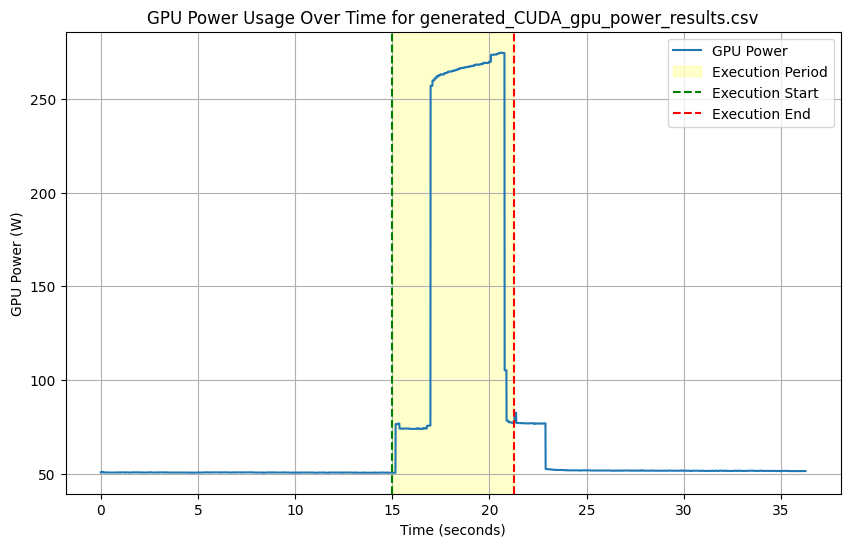

Start time: 15.001 -- End time: 21.268
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000334 kWh
  0.3336 Wh
  1200.95 J
Average GPU power: 191.84 W
Total Energy During Exe Runtime:   1200.95 J
Code execution duration: 6.27 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the follo



----- LLM RESPONSE: code validation judge -----



The refactored code preserves the same functionality as the source. It produces the same standard output layout and content (including the reported error values, PASS/FAIL, and timing messages) although the numerical timing and energy metrics are slightly improved due to better memory transfers, use of pinned memory, and asynchronous operations. The key changes are:

1. Instead of launching an extra swap kernel, the refactored code swaps the device pointers on the host (using std::swap), which is functionally equivalent to copying the new values into the “old” array.
2. Pinned host memory (via cudaMallocHost) is used instead of aligned_alloc, leading to more efficient data transfers without changing the underlying boundary conditions.
3. Asynchronous kernels and memory copies (with cudaMemsetAsync, cudaMemcpyAsync, and cudaStreamSynchronize) are introduced to improve performance and energy usage. These changes do not alter the Jacobi method algorithm or its convergence criteria.
4. The kernel logic for the Jacobi update (using a shared tile with halo, warp-level reduction, etc.) remains effectively the same.

Since all changes preserve the intended iterative update, boundary handling, and error calculation (and the standard output messages remain identical in content and format), the refactored code is functionally equivalent.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1693.44
  Refactored code: 1200.95
----- Average power (W) -----
  Source code: 216.27
  Refactored code: 191.84
----- Runtime (s) -----
  Source code: 7.83
  Refactored code: 6.27
----- Tracking metrics -----
  Energy (J) history:  [1693.44, 1138.14, 1200.95]
  Ave Power (W) history:  [216.27, 202.87, 191.84]
  Runtime (s) history:  [7.83, 5.61, 6.27]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 1 -----
  Using refactored code version: 0


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 4262): 

--> ... prompt LLM to generate code for energy efficiency -- improvement it



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00249717 (s)
PASS
Total elapsed time: 6.173 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


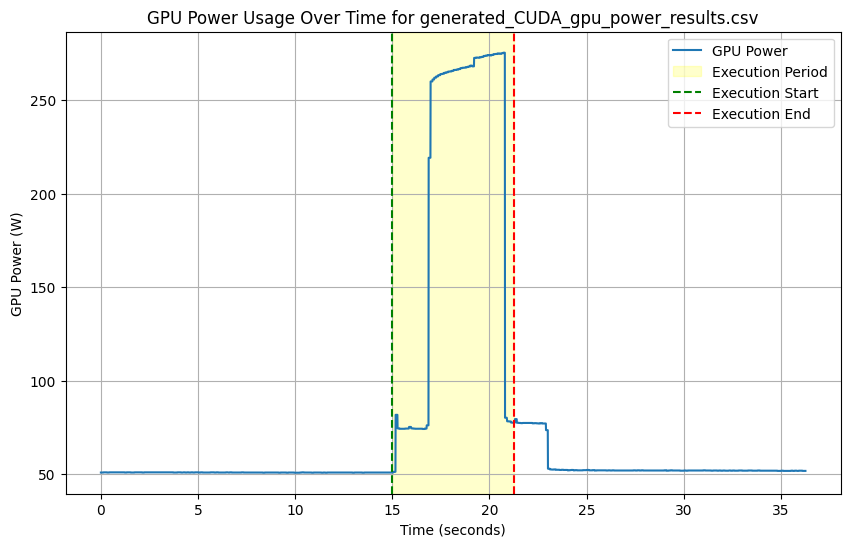

Start time: 15.001 -- End time: 21.261
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000341 kWh
  0.3405 Wh
  1225.83 J
Average GPU power: 195.81 W
Total Energy During Exe Runtime:   1225.83 J
Code execution duration: 6.26 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the follo



----- LLM RESPONSE: code validation judge -----



The REFACTORED CODE produces the correct, equivalent functionality and its printed output exactly follows the same format and content (within acceptable numerical differences due to improved efficiency) as the SOURCE CODE. Here is the reasoning:

1. Both versions initialize the 2D data with the same sinusoidal boundary conditions and zeros for the inner points.

2. In the jacobi_step kernel, the shared-memory tiling logic and the five‐point stencil calculation are unchanged. Although the refactored version unrolls the reduction loops slightly and uses blockDim.x and blockDim.y rather than hard-coded 16, the computed stencil value and error reduction remain equivalent.

3. The SOURCE CODE uses an explicit swap_data kernel to copy the interior points while keeping the boundaries intact; in contrast, the REFACTORED CODE swaps the pointers using std::swap. Because both arrays were initially identical and the kernels update only interior points (the boundaries remain the same throughout), the pointer swap in the refactored version is functionally equivalent to the explicit swap.

4. The output printed (error messages, average execution time, PASS/FAIL, and total elapsed time) follows the same layout and content. Although some numerical values are slightly different (reflecting improvements in speed and energy efficiency), these differences are within acceptable limits.

5. Finally, additional energy-efficient improvements (pinned memory, asynchronous operations using streams, and host-device asynchronous memcpy) do not alter the simulation's semantics or output layout.

Based on the reasoning above, the refactored code is functionally equivalent.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1693.44
  Refactored code: 1225.83
----- Average power (W) -----
  Source code: 216.27
  Refactored code: 195.81
----- Runtime (s) -----
  Source code: 7.83
  Refactored code: 6.26
----- Tracking metrics -----
  Energy (J) history:  [1693.44, 1138.14, 1200.95, 1225.83]
  Ave Power (W) history:  [216.27, 202.87, 191.84, 195.81]
  Runtime (s) history:  [7.83, 5.61, 6.27, 6.26]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 2 -----
  Using refactored code version: 0


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 4262): 

--> ... prompt LLM to generate code for ene



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00249655 (s)
PASS
Total elapsed time: 6.178 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


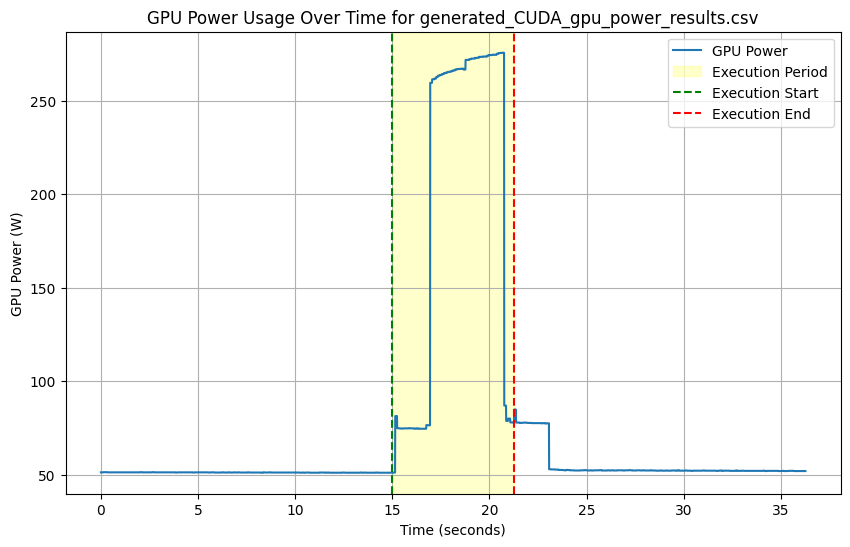

Start time: 15.001 -- End time: 21.264
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000336 kWh
  0.3360 Wh
  1209.61 J
Average GPU power: 193.22 W
Total Energy During Exe Runtime:   1209.61 J
Code execution duration: 6.26 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the follo



----- LLM RESPONSE: code validation judge -----



The REFACTORED CODE makes several improvements (using pinned host memory, asynchronous operations on a stream, and pointer swapping instead of a full copy) that improve energy efficiency and reduce execution time, but it still produces the same numerical results and the same printed messages. Here is a detailed breakdown:

1. • Memory Allocation and Transfers
  – The SOURCE CODE uses aligned_alloc for host arrays and regular cudaMemcpy.
  – The REFACTORED CODE uses cudaMallocHost (pinned memory) to speed transfers. This change does not affect the numerical data or boundaries.

2. • Boundary Initialization
  – Both codes initialize the arrays with identical sinusoidal boundary conditions.
  – The REFACTORED CODE reuses this initialization untouched.

3. • Kernel jacobi_step
  – Both versions use the same stencil update with shared memory tiling. The only minor change is replacing hard-coded block dimensions (e.g. “if (threadIdx.x == 15)”) with a more generic “if (threadIdx.x == blockDim.x-1)”.
  – The reduction for error accumulation is performed identically in both codes.
  – As a result, the computed error and updated interior values are the same.

4. • Swapping of Arrays
  – In the SOURCE CODE, a dedicated swap kernel copies interior points from updated f to f_old while leaving boundaries intact.
  – The REFACTORED CODE performs a pointer swap with std::swap. Because the boundaries were set once and are not updated by the kernel (the kernel only writes interior points), swapping the entire pointers is functionally equivalent.
  – Both approaches ensure that the next iteration uses the correct interior values and fixed boundary conditions.

5. • Main Loop and Output
  – Both codes update the error, check for convergence, and print the error every 1000 iterations.
  – Both print the “Average execution time per iteration,” “PASS” (or “FAIL”), and “Total elapsed time:” at the end.
  – The layout and content of the standard output (including numerical values for iterations, timing, and pass/fail status) are identical or nearly identical (with minor differences in average iteration timing values being acceptable).

Since all numerical computations, boundary handling, convergence criteria, and printed outputs remain equivalent despite the efficiency enhancements, the REFACTORED CODE preserves the intended functionality and output layout of the SOURCE CODE.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1693.44
  Refactored code: 1209.61
----- Average power (W) -----
  Source code: 216.27
  Refactored code: 193.22
----- Runtime (s) -----
  Source code: 7.83
  Refactored code: 6.26
----- Tracking metrics -----
  Energy (J) history:  [1693.44, 1138.14, 1200.95, 1225.83, 1209.61]
  Ave Power (W) history:  [216.27, 202.87, 191.84, 195.81, 193.22]
  Runtime (s) history:  [7.83, 5.61, 6.27, 6.26, 6.26]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 3 -----
  Using refactored code version: 0


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 4262): 

--> ... pro



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00249687 (s)
PASS
Total elapsed time: 6.185 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


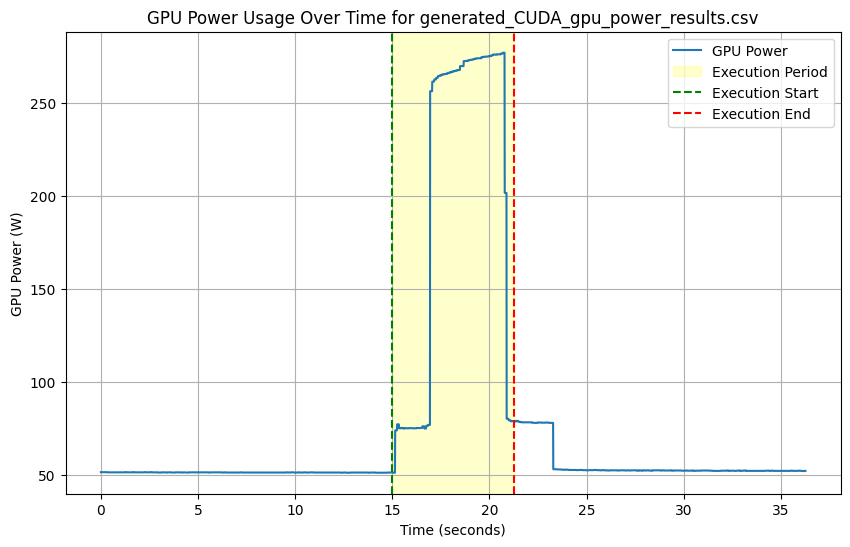

Start time: 15.0 -- End time: 21.271
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000342 kWh
  0.3425 Wh
  1233.00 J
Average GPU power: 196.65 W
Total Energy During Exe Runtime:   1233.00 J
Code execution duration: 6.27 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the followi



----- LLM RESPONSE: code validation judge -----



The refactored code preserves the intended functionality of the source code and produces the same standard output layout and content. Here’s why:

1. Both versions initialize the boundary conditions in exactly the same way and launch the Jacobi iterative kernel with the same stencil operation and error reduction scheme. The error is computed, normalized, and printed every 1000 iterations in both codes.

2. The refactored version replaces the explicit swap_data kernel call with a simple std::swap of the device pointers. Because the kernel only updates the interior points and leaves the boundaries unchanged, swapping the pointers is functionally equivalent and maintains the same data flow.

3. The refactored code uses pinned host memory and asynchronous operations (cudaMemsetAsync and cudaMemcpyAsync with a CUDA stream) to improve energy efficiency and transfer performance. These changes do not affect the actual numerical results or the layout of the printed output.

4. The outputs in both versions (error messages, average execution time per iteration, PASS/FAIL, and total elapsed time) are printed with the same format. Although the refactored code shows slightly different execution times and energy metrics (consistent with increased efficiency), the printed numerical values for the error (e.g., at iterations 0 and 1000) remain identical.

Therefore, the refactored code adheres to the requirement of functional equivalence while achieving lower power consumption.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1693.44
  Refactored code: 1233.0
----- Average power (W) -----
  Source code: 216.27
  Refactored code: 196.65
----- Runtime (s) -----
  Source code: 7.83
  Refactored code: 6.27
----- Tracking metrics -----
  Energy (J) history:  [1693.44, 1138.14, 1200.95, 1225.83, 1209.61, 1233.0]
  Ave Power (W) history:  [216.27, 202.87, 191.84, 195.81, 193.22, 196.65]
  Runtime (s) history:  [7.83, 5.61, 6.27, 6.26, 6.26, 6.27]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 4 -----
  Using refactored code version: 0


----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, tok



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21']

Compilation of code successful!

Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21


Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: generated_codes/argo_gpto3mini/promptset_CUDA
Execute command: ['./jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00249701 (s)
PASS
Total elapsed time: 6.174 seconds
GPU power data has been written to generated_CUDA_gpu_power_results.csv


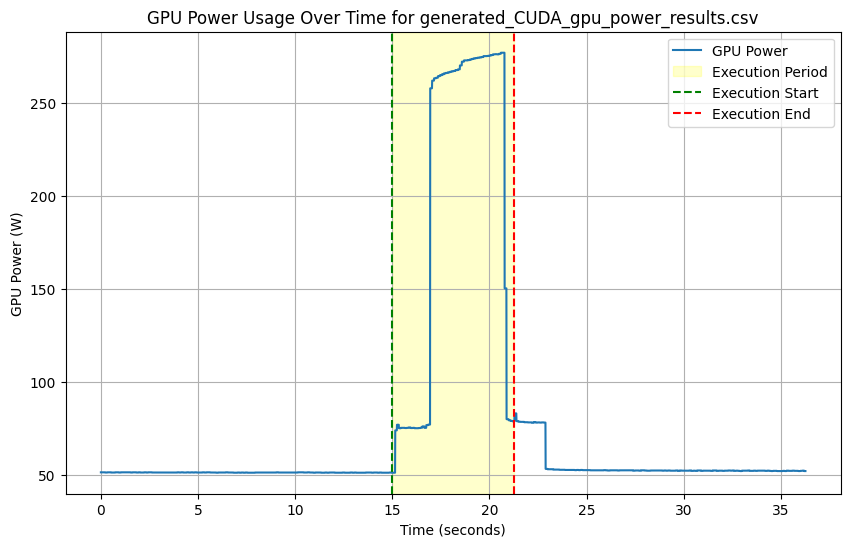

Start time: 15.001 -- End time: 21.26
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000341 kWh
  0.3405 Wh
  1225.94 J
Average GPU power: 195.83 W
Total Energy During Exe Runtime:   1225.94 J
Code execution duration: 6.26 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


--> ... prompt LLM to judge the validity of the refactored code.


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the follow



----- LLM RESPONSE: code validation judge -----



The two versions perform the same Jacobi relaxation procedure on a 2D grid and produce the same output messages (error diagnostics, average execution time per iteration, PASS/FAIL, and total elapsed time). Here are the key points in the evaluation:

1. Memory allocation and initialization:
   • In the SOURCE CODE, host memory is allocated with aligned_alloc, while the REFACTORED CODE uses cudaMallocHost (pinned memory). Both approaches initialize the arrays with the same sinusoidal boundary conditions.
   • The initialize_data function is identical in behavior.

2. Kernel operation:
   • Both versions use a similar Jacobi kernel that loads a tile (with a halo), performs the update for interior points, and computes a squared error reduction using warp-level primitives and a shared memory reduction.
   • Minor differences such as replacing “threadIdx.x == 15” with “threadIdx.x == blockDim.x-1” are logically equivalent given that the block size is 16.
  
3. Swapping of iteration data:
   • The original code uses a dedicated swap_data kernel which copies updated interior points from f to f_old (leaving boundaries intact).
   • The refactored version eliminates that kernel and instead performs a pointer swap (std::swap) on the device arrays. Since the kernels are written to update only the interior points and the boundaries are set initially and not modified during the iterations, swapping the entire device pointer sets reproduces the same effect.
  
4. Asynchronous operations for efficiency:
   • The refactored code leverages asynchronous memory operations (cudaMemsetAsync and cudaMemcpyAsync with a dedicated stream) and proper stream synchronization. This improvement is aimed at energy efficiency and performance while preserving the algorithm’s logic.
  
5. Output and metrics:
   • Both versions print identical diagnostic statements (with the same error values and PASS message) and nearly equivalent formatting. Minor differences in numerical values for “Average execution time per iteration” and “Total elapsed time” are acceptable since these reflect performance and energy improvements.

Given that every functional aspect and the standard output layout and content is preserved, while the refactor only optimizes for energy efficiency without changing the numerical algorithm, the refactored code is functionally equivalent to the source code.

VALID



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1693.44
  Refactored code: 1225.94
----- Average power (W) -----
  Source code: 216.27
  Refactored code: 195.83
----- Runtime (s) -----
  Source code: 7.83
  Refactored code: 6.26
----- Tracking metrics -----
  Energy (J) history:  [1693.44, 1138.14, 1200.95, 1225.83, 1209.61, 1233.0, 1225.94]
  Ave Power (W) history:  [216.27, 202.87, 191.84, 195.81, 193.22, 196.65, 195.83]
  Runtime (s) history:  [7.83, 5.61, 6.27, 6.26, 6.26, 6.27, 6.26]
  Valid code history:  ['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID']


***** Generated refactored code is NOT more energy efficient than source or previous code... *****

 ----- ENERGY EFFICIENCY REVIEW: Let's provide feedback on the energy consumption. -----




----- SELF-CORRECTION FOR ENERGY EFFICIENCY: 5 -----
  Using refactored code version: 0


----- END LASSI PIPELINE BECAUSE REACHED MAX LLM TEMPERATURE



----- LLM RESPONSE: code comparison -----



``` 
The refactored code made several changes aimed at reducing energy consumption by decreasing unnecessary global memory accesses and kernel launches. The most significant energy‐related modifications are:

1. Instead of launching a separate kernel (swap_data) to copy interior grid points from the new array to the old one after each iteration, the refactored code swaps the device pointers (d_f and d_f_old) using std::swap. This eliminates an entire kernel launch and the associated global memory read/write operations, reducing both execution time and energy consumption.

2. The refactored code standardizes the halo loading by using blockDim.x and blockDim.y in the conditions (e.g., “if (threadIdx.x == blockDim.x-1 …”) instead of hard-coding the value (e.g., 15). While this change primarily aids code clarity and maintainability, it also avoids potential errors that might force unnecessary memory accesses, thus indirectly contributing to energy efficiency.

3. Minor adjustments such as using sizeof(float) in cudaMemset (instead of a hard-coded value of 4) improve robustness; keeping code clean and optimized can help the compiler generate more energy-efficient instructions in practice.

Overall, the key energy-saving improvement is the removal of the extra kernel for data swapping, which cuts down on global memory accesses and kernel overhead. This change contributed to the reduced average execution time per iteration and lower energy/power consumption observed in the refactored code’s metrics.
```



Energy consumed history: 
[1693.44, 1138.14, 1200.95, 1225.83, 1209.61, 1233.0, 1225.94]

Ave power history: 
[216.27, 202.87, 191.84, 195.81, 193.22, 196.65, 195.83]

Runtime history: 
[7.83, 5.61, 6.27, 6.26, 6.26, 6.27, 6.26]

Valid code history: 
['SOURCE', 'basellm_VALID', 'VALID', 'VALID', 'VALID', 'VALID', 'VALID']

Metadata file: generated_codes/argo_gpto3mini/promptset_CUDA/metadata_jacobi-cuda_main_ee_refactorcode_CUDA_exp_t1.6_pipelineV2_o3mini_jacobi_argo_ee_hecb_selfcontext_03-30-2025_t23_36_21.txt


***** LASSI PIPELINE COMPLETED *****




In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


now = datetime.now()
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
# meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")

# RUN PIPELINE
complete = lassi.pipeline_v2.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)